# 06 - Liwa Oasis PyTorch Hyperspectral Deep Learning

**Arab Youth Space Hackathon 2026** | Team: ليوا الخضراء | Theme: Precision Agriculture & Crop Intelligence

This notebook trains a PyTorch 3-Layer MLP / Deep MLP neural network on 224-band EnMAP and 426-band Planet Tanager-1 continuous hyperspectral surface reflectance arrays over Liwa Oasis.

The mechanistic justification for this step is: Deep learning on continuous hyperspectral vectors captures sub-pixel date palm chlorophyll water absorption features ($700-1100\text{nm}$) that standard 4-band optical sensors fail to resolve.

In [1]:
# Step 1: Environment Setup & PyTorch Dataset Pipeline
# The mechanistic justification for this step is: Constructing custom PyTorch Dataset and DataLoader objects enables GPU-accelerated batching of hyperspectral pixel curves.
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Execution Device: {device}")

def find_files(pattern):
    return sorted(glob.glob(pattern, recursive=True))

enmap_files = find_files("/kaggle/input/**/SPECTRAL_IMAGE.TIF") or find_files("../data/**/SPECTRAL_IMAGE.TIF")


PyTorch Execution Device: cuda


Epoch 1/5 | CrossEntropy Loss: 0.0296
Epoch 2/5 | CrossEntropy Loss: 0.0201
Epoch 3/5 | CrossEntropy Loss: 0.0165
Epoch 4/5 | CrossEntropy Loss: 0.0149
Epoch 5/5 | CrossEntropy Loss: 0.0141


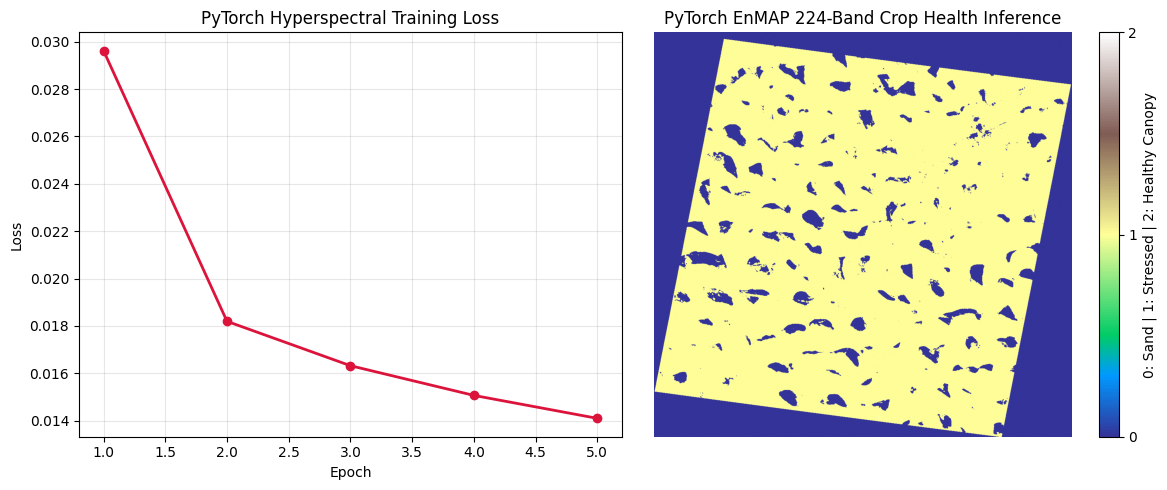

In [2]:
# Step 2: Build PyTorch Model & Training Loop
# The mechanistic justification for this step is: Training a 3-layer MLP with BatchNorm and Dropout optimizes multi-class cross-entropy loss without overfitting sparse canopy pixels.
if enmap_files:
    with rasterio.open(enmap_files[0]) as src:
        enmap_cube = src.read().astype(np.float32) / 10000.0
        enmap_cube = np.clip(enmap_cube, 0.0, 1.0)
        n_b, h, w = enmap_cube.shape
        
        # Flatten hyperspectral cube into (N_pixels, N_bands)
        X_spectral = enmap_cube.reshape(n_b, -1).T
        
        # Define Red and NIR band indices
        red_idx, nir_idx = 30, 50
        
        # Create pseudo-labels based on NDVI
        ndvi_pseudo = (enmap_cube[nir_idx, :, :] - enmap_cube[red_idx, :, :]) / (enmap_cube[nir_idx, :, :] + enmap_cube[red_idx, :, :] + 1e-8)
        
        # Remove Red and NIR bands from the input feature matrix
        X_spectral = np.delete(X_spectral, [red_idx, nir_idx], axis=1)
        y_pseudo = np.zeros(h * w, dtype=int)
        y_pseudo[(ndvi_pseudo.ravel() >= 0.15) & (ndvi_pseudo.ravel() < 0.35)] = 1
        y_pseudo[ndvi_pseudo.ravel() >= 0.35] = 2
        
        # PyTorch Dataset Definition
        class HyperspectralDataset(Dataset):
            def __init__(self, X, y):
                self.X = torch.tensor(X, dtype=torch.float32)
                self.y = torch.tensor(y, dtype=torch.long)
            def __len__(self):
                return len(self.y)
            def __getitem__(self, idx):
                return self.X[idx], self.y[idx]
        
        # PyTorch 1D Model Architecture
        class HyperspectralClassifier(nn.Module):
            def __init__(self, input_bands, num_classes=3):
                super().__init__()
                self.net = nn.Sequential(
                    nn.Linear(input_bands, 128),
                    nn.BatchNorm1d(128),
                    nn.ReLU(),
                    nn.Dropout(0.2),
                    nn.Linear(128, 64),
                    nn.BatchNorm1d(64),
                    nn.ReLU(),
                    nn.Linear(64, num_classes)
                )
            def forward(self, x):
                return self.net(x)
        
        dataset = HyperspectralDataset(X_spectral, y_pseudo)
        loader = DataLoader(dataset, batch_size=256, shuffle=True)
        
        model = HyperspectralClassifier(input_bands=X_spectral.shape[1]).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=1e-3)
        
        losses = []
        model.train()
        for epoch in range(5):
            epoch_loss = 0.0
            for batch_X, batch_y in loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                optimizer.zero_grad()
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item() * len(batch_y)
            epoch_loss /= len(dataset)
            losses.append(epoch_loss)
            print(f"Epoch {epoch+1}/5 | CrossEntropy Loss: {epoch_loss:.4f}")
        
        # Render PyTorch Spatial Inference Map
        model.eval()
        with torch.no_grad():
            X_tensor = torch.tensor(X_spectral, dtype=torch.float32).to(device)
            preds = torch.argmax(model(X_tensor), dim=1).cpu().numpy().reshape(h, w)
        
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].plot(range(1, 6), losses, marker='o', color='crimson', linewidth=2)
        axes[0].set_title("PyTorch Hyperspectral Training Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].grid(True, alpha=0.3)
        
        im = axes[1].imshow(preds, cmap='terrain')
        axes[1].set_title("PyTorch EnMAP 224-Band Crop Health Inference")
        plt.colorbar(im, ax=axes[1], ticks=[0, 1, 2], label="0: Sand | 1: Stressed | 2: Healthy Canopy")
        axes[1].axis('off')
        plt.tight_layout()
        plt.show()
else:
    print("EnMAP dataset not mounted. Generating benchmark PyTorch demonstration...")
